# Lab 16: VEGAS tutorial

Remember when we used Monte Carlo to estimate an integral?

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from math import erf
from numba import njit
from IPython.display import HTML, display

display(HTML("""
<style>
/* Place plotting code and its output beside each other in RISE. */
.reveal .slides .jp-CodeCell:has(.jp-RenderedImage) {
    display: grid !important;
    grid-template-columns: 47% 53%;
    align-items: start;
}

.reveal .slides .jp-CodeCell:has(.jp-RenderedImage) > .jp-Cell-inputWrapper {
    display: block !important;
    grid-column: 1;
    grid-row: 1;
    min-width: 0;
}

.reveal .slides .jp-CodeCell:has(.jp-RenderedImage) > .jp-Cell-outputWrapper {
    grid-column: 2;
    grid-row: 1;
    min-width: 0;
    width: 100%;
    position: sticky !important;
    top: 12px;
    align-self: start;
}

/* Wrap long code lines within the left column. */
.reveal .slides .jp-CodeCell:has(.jp-RenderedImage) .cm-content {
    white-space: break-spaces !important;
    overflow-wrap: anywhere !important;
}

/* Fit the plot within the right column. */
.reveal .slides .jp-CodeCell:has(.jp-RenderedImage) img {
    width: 100% !important;
    max-width: 100%;
    height: auto;
    object-fit: contain;
}
</style>
"""))

## btw
Remember, all we're doing is approximating integrals with something *like* Riemann sums:
$$\int_{x_{min}}^{x_{max}}h({x_i}) dx \approx \sum_i h({x_i}) dx.$$

The thing we're using that is *like* Riemann sums is the Monte Carlo method.
$$d x = (x_{max} - x_{min})/N$$
where $N$ is the number of samples.
It's not too much of a leap to see that as $N$ approaches infinity, and as long as $x_i$ is sampled uniformly from between $x_{min}$ and $x_{max}$, then both methods will approach the same answer.

Anyways, next then,
$$\sum_i h({x_i}) dx = \sum_i h({x_i}) (x_{max} - x_{min})/N = (x_{max} - x_{min})(\frac{1}{N}\sum_i h({x_i})).$$

This last statement here can be interperted as
$$(x_{max} - x_{min})(\frac{1}{N}\sum_i h({x_i})) = \text{width} \cdot \text{sampled mean height} \approx \text{width} \cdot \text{global average height}$$

Since these values are independently sampled, the standard error is just the "naive" error,
$$\text{SE}\left(\text{width} \cdot \text{sampled mean height}\right) = \text{width} \cdot \text{SE}\left(\text{sampled mean height}\right) = \text{width} \cdot \frac{s_h}{\sqrt{N}}$$

## For Example

### A peak with a known area

On the interval \\(0\leq x\leq 1\\), use a Gaussian peak on a constant background:

\\[ h(x)=b+\frac{A}{\sigma\sqrt{2\pi}} \exp\left[-\frac{(x-\mu)^2}{2\sigma^2}\right]. \\]

With parameters:

\\[ b=0.1,\qquad A=0.9,\qquad \mu=0.63,\qquad \sigma=0.12. \\]

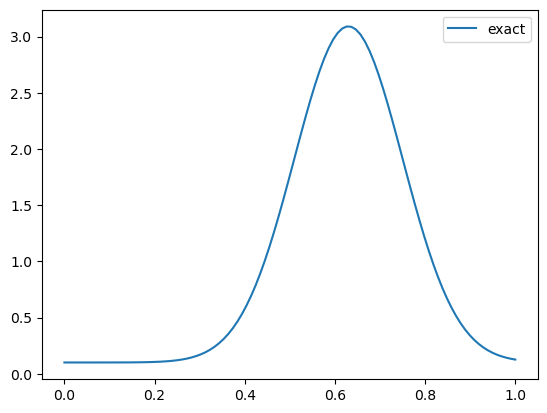

In [3]:
@njit
def toy(x, b, A, mu, sigma):
    return b + A*np.exp(-0.5*((x-mu)/sigma)**2)/(sigma*np.sqrt(2*np.pi))

xmin = 0
xmax = 1
x = np.linspace(xmin, xmax, 100)

b = 0.1
A = 0.9
mu = 0.63
sigma = 0.12

y = toy(x, b, A, mu, sigma)

plt.plot(x, y, label='exact')
plt.legend()
plt.show()

### Then uniformly sample from between $x_{min}$ and $x_{max}$

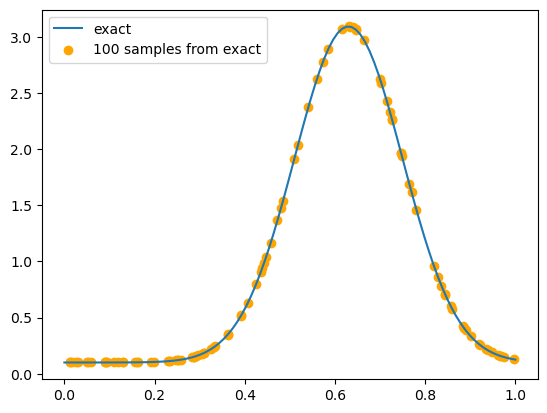

In [4]:
num_samples = 100
x_distribution = np.random.uniform(xmin, xmax, size=num_samples)
y_distribution = toy(x_distribution, b, A, mu, sigma)

plt.plot(x, y, label='exact')
plt.scatter(
    x_distribution, 
    y_distribution, 
    color = 'orange', 
    label=f'{num_samples} samples from exact'
)
plt.legend()
plt.show()

### Then multiply each $h(x_i)$ by the width $d x = (x_{max} - x_{min})/N$

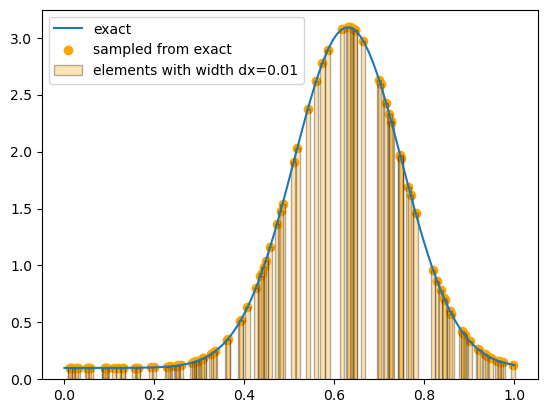

In [5]:
plt.plot(x, y, label='exact')
plt.scatter(
    x_distribution, 
    y_distribution, 
    color = 'orange', 
    label='sampled from exact'
)

dx = (xmax - xmin)/num_samples 
plt.bar(
    x_distribution,
    height=y_distribution,
    width=dx,
    align='center',
    color='orange',
    edgecolor='black',
    alpha=0.3,
    label=f'elements with width dx={dx}'
)

plt.legend()
plt.show()

### Then add all those rectangles together to get the approximate area.

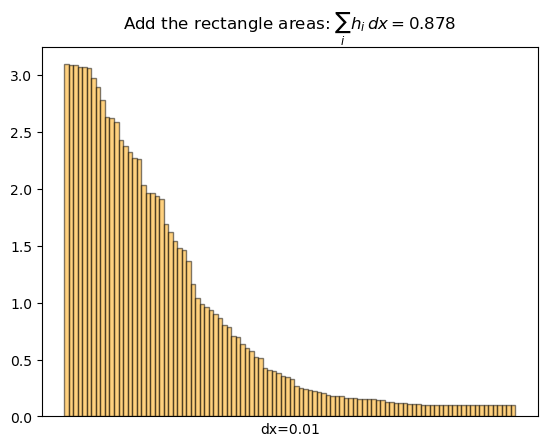

In [6]:
heights = np.sort(y_distribution)[::-1]
positions = xmin + dx * np.arange(len(heights))
total_area = dx * np.sum(heights)

plt.bar(
    positions, heights,
    width=dx, align='edge',
    color='orange', edgecolor='black', alpha=0.5,
)

plt.xticks([])
plt.title(
    rf"Add the rectangle areas: $\sum_i h_i\,d x = {total_area:.3f}$"
)
plt.xlabel(f'dx={dx}')
plt.show()

In [7]:
@njit
def _sample_toy_area(num_samples, rng, xmin, xmax, b, A, mu, sigma, keep_samples):
    count = num_samples if keep_samples else 0
    xs = np.empty(count)
    ys = np.empty(count)
    total = 0.0
    mean = 0.0
    m2 = 0.0

    for i in range(num_samples):
        xi = rng.uniform(xmin, xmax)
        yi = toy(xi, b, A, mu, sigma)
        total += yi
        delta = yi - mean
        mean += delta / (i + 1)
        m2 += delta * (yi - mean)
        if keep_samples:
            xs[i] = xi
            ys[i] = yi

    area = (xmax - xmin) * total / num_samples
    standard_error = (xmax - xmin) * np.sqrt(
        (m2 / (num_samples - 1)) / num_samples
    )
    return area, standard_error, xs, ys


def plot_toy_area(
    num_samples, seed,
    b, A, mu, sigma, xmin, xmax, make_plots,
):
    """Return (area, standard_error, fig, axes); plot values are None without plots."""
    if not isinstance(num_samples, (int, np.integer)) or num_samples < 2:
        raise ValueError("num_samples must be an integer of at least 2.")
    if xmax <= xmin:
        raise ValueError("xmax must be greater than xmin.")
    if sigma <= 0:
        raise ValueError("sigma must be positive.")

    rng = np.random.default_rng(seed)
    area, standard_error, x_distribution, y_distribution = _sample_toy_area(
        num_samples, rng, xmin, xmax, b, A, mu, sigma, make_plots
    )
    if not make_plots:
        return area, standard_error, None, None

    x = np.linspace(xmin, xmax, int(100 / sigma))
    y = toy(x, b, A, mu, sigma)
    dx = (xmax - xmin) / num_samples
    heights = np.sort(y_distribution)[::-1]
    positions = xmin + dx * np.arange(num_samples)

    fig, axes = plt.subplots(
        1, 3, figsize=(14, 4.5), sharey=True, layout="constrained"
    )
    fig.suptitle(f"Monte Carlo integration with {num_samples} samples", fontsize=16)

    axes[0].plot(x, y, color="tab:blue", linewidth=2)
    axes[0].fill_between(x, y, color="tab:blue", alpha=0.10)
    axes[0].set_title("1. The function")
    axes[0].set_ylabel(r"$f(x)$")
    axes[0].set_xlabel("x")

    axes[1].plot(x, y, color="tab:blue", linewidth=2, label=r"$f(x)$")
    axes[1].bar(
        x_distribution, y_distribution, width=dx, align="center",
        color="orange", edgecolor="black", linewidth=0.5, alpha=0.30,
    )
    axes[1].scatter(
        x_distribution, y_distribution, color="darkorange",
        s=35, zorder=3, label="Uniform x samples",
    )
    axes[1].set_title("2. Sample and draw rectangles")
    axes[1].set_xlabel("x")
    axes[1].legend(frameon=False, fontsize=9, loc="upper left")

    axes[2].bar(
        positions, heights, width=dx, align="edge",
        color="orange", edgecolor="black", linewidth=0.5, alpha=0.60,
    )
    axes[2].set_title("3. Sort and add their areas")
    axes[2].set_xticks([])
    axes[2].set_xlabel(rf"Each rectangle has width $dx = {dx:.3g}$")
    axes[2].text(
        0.97, 0.93,
        r"$\mathrm{Total\ area} = dx\sum_i h_i$"
        "\n" + r"$= {:.4f}\,\pm\,{:.4f}$".format(area, standard_error),
        transform=axes[2].transAxes,
        ha="right", va="top", fontsize=13,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.9),
    )

    for ax in axes:
        ax.set_xlim(xmin - dx / 2, xmax + dx / 2)
        ax.set_ylim(0, 1.22 * np.max(y))
        ax.set_axisbelow(True)
        ax.grid(axis="y", alpha=0.2)
        ax.spines[["top", "right"]].set_visible(False)

    for ax in axes[1:]:
        for rectangle in ax.patches:
            width = rectangle.get_width()
            height = rectangle.get_height()
            ax.text(
                rectangle.get_x() + width / 2,
                rectangle.get_y() + height / 2,
                f"{width * height:.3g}",
                ha="center", va="center", fontsize=8, zorder=4,
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=1),
            )

    return area, standard_error, fig, axes

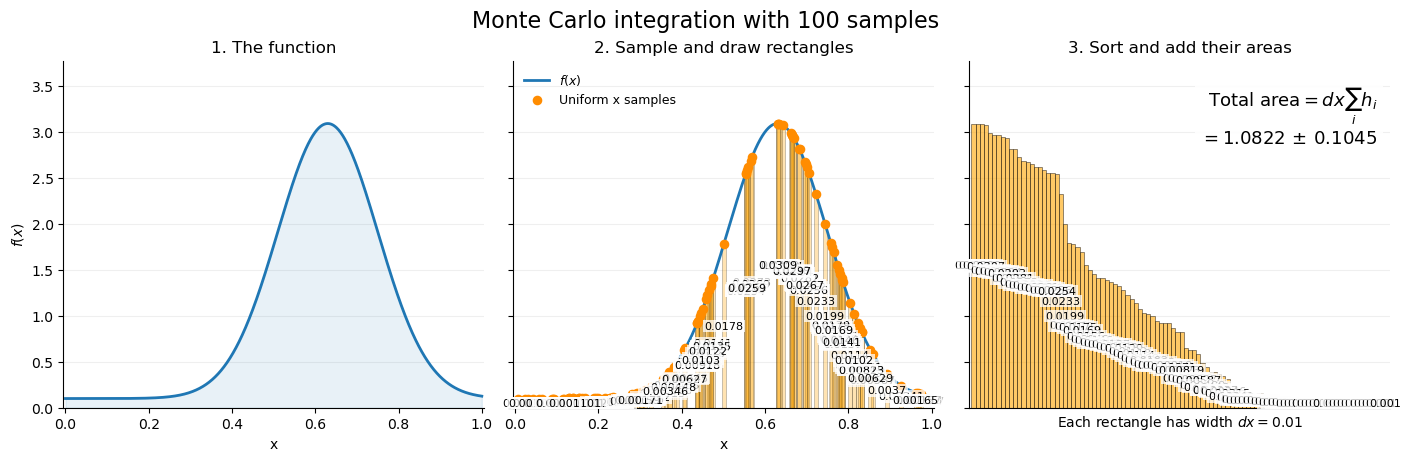

In [8]:
area, se, fig, axes = plot_toy_area(    
    num_samples = 100,
    seed=42,
    xmin = 0,
    xmax = 1,
    b = 0.1,
    A = 0.9,
    mu = 0.63,
    sigma = 0.12,
    make_plots=True
)
plt.show()

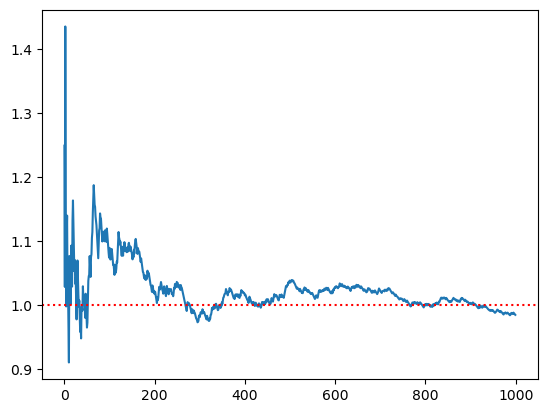

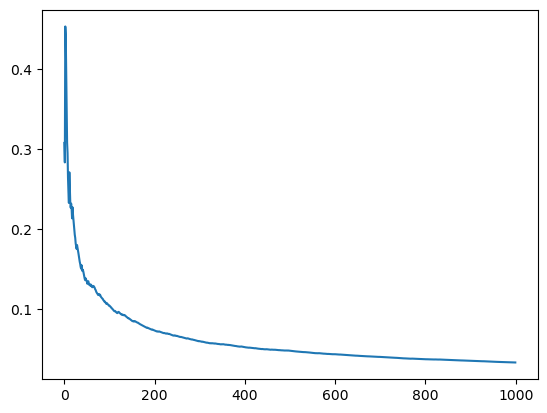

In [9]:
areas1 = []
ses1 = []
for i in range(1000):
    area, se, _, _ = plot_toy_area(    
        num_samples = (i+2),
        seed=42,
        xmin = 0,
        xmax = 1,
        b = 0.1,
        A = 0.9,
        mu = 0.63,
        sigma = 0.12,
        make_plots=False
    )
    areas1.append(area)
    ses1.append(se)

plt.plot(areas1, label='sampled area as a function of sample size')
plt.axhline(y=1.0, color='red', linestyle=':', label='true area = .9991')
plt.show()

plt.plot(ses1, label='standard error as a function of sample size')
plt.show()

### All of that was recap.

## Ok, but what if gaussian skinny??

### uh oh, a lot of misses. it's hard for a uniform sample to actually land at the spike. And if it does, it can easily overpower all the other values.

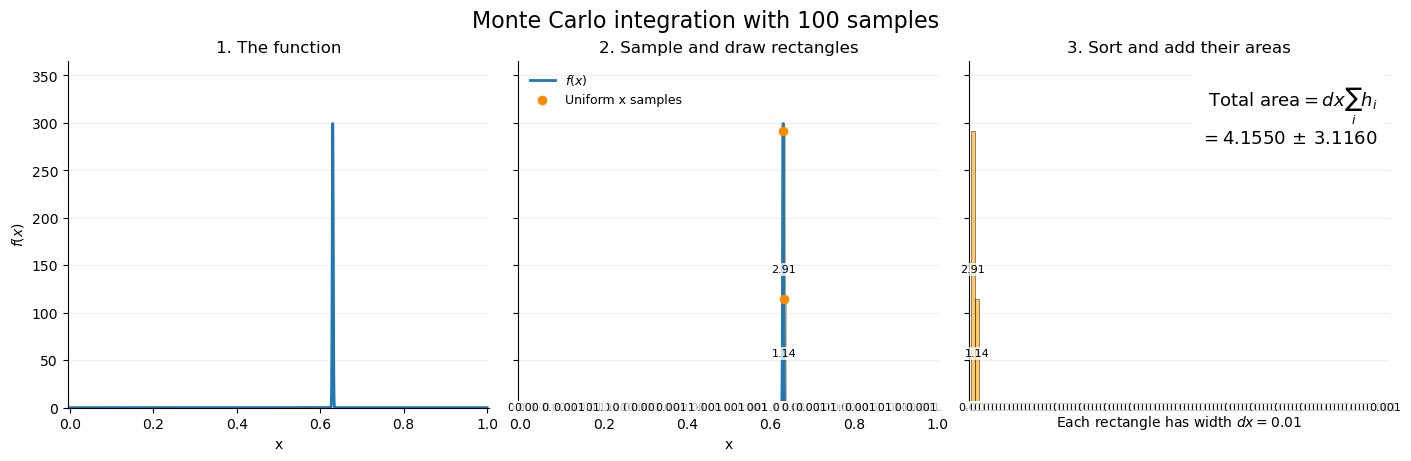

In [10]:
area, se, fig, axes = plot_toy_area(    
    num_samples = 100,
    seed= 42,
    xmin = 0,
    xmax = 1,
    b = 0.1,
    A = 0.9,
    mu = 0.63,
    sigma = 0.0012, ## make this a lot smaller??????
    make_plots=True
)
plt.show()

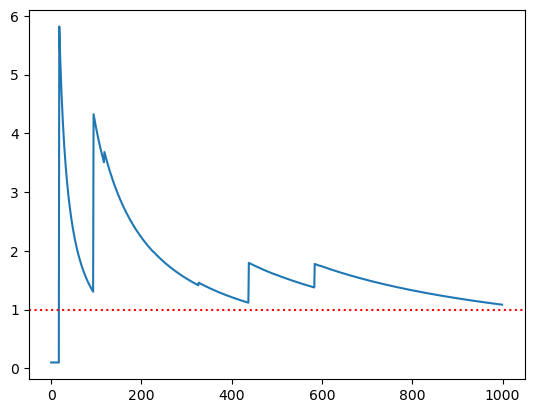

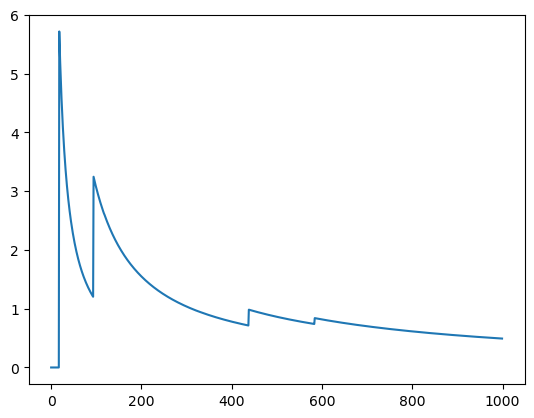

In [11]:
areas2 = []
ses2 = []
for i in range(1000):
    area, se, _, _ = plot_toy_area(    
        num_samples = (i+2),
        seed=42,
        xmin = 0,
        xmax = 1,
        b = 0.1,
        A = 0.9,
        mu = 0.63,
        sigma = 0.0012,
        make_plots=False
    )
    areas2.append(area)
    ses2.append(se)

plt.plot(areas2, label='sampled area as a function of sample size')
plt.axhline(y=1.0, color='red', linestyle=':', label='true area = .9991')
plt.show()

plt.plot(ses2, label='standard error as a function of sample size')
plt.show()

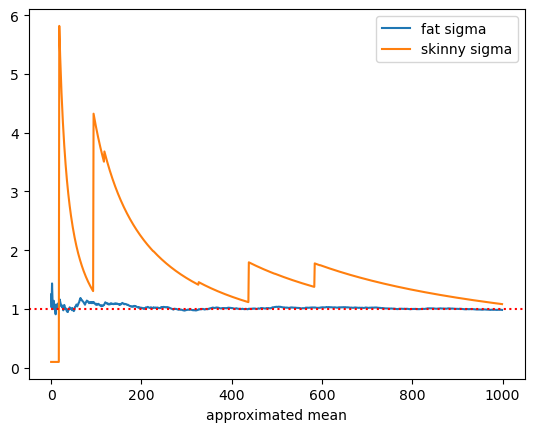

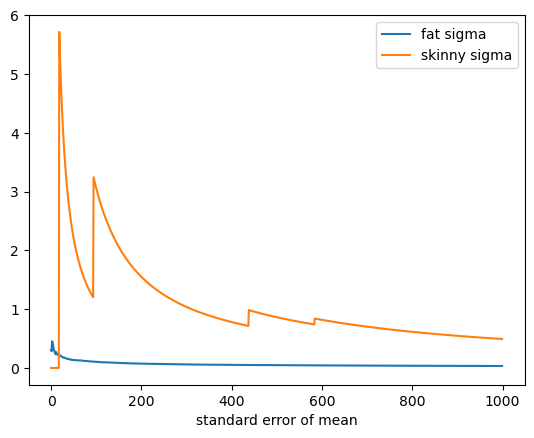

In [12]:
plt.plot(areas1, label='fat sigma')
plt.plot(areas2, label='skinny sigma')
plt.axhline(y=1.0, color='red', linestyle=':')
plt.legend()
plt.xlabel('sample size')
plt.xlabel('approximated mean')
plt.show()

plt.plot(ses1, label='fat sigma')
plt.plot(ses2, label='skinny sigma')
plt.legend()
plt.xlabel('sample size')
plt.xlabel('standard error of mean')
plt.show()

## Repeat the experiment

Each point below uses 100 new uniform samples. Bars show one estimated standard error.

A run that barely samples the peak can underestimate both its area and its uncertainty. Increasing the sample count helps, but most evaluations still land away from the peak.


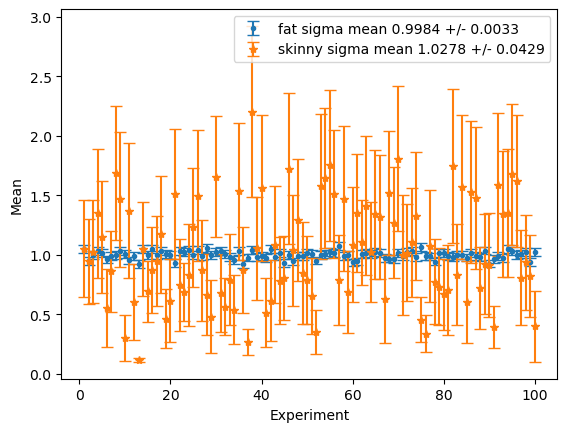

In [13]:
experiment_means1 = []
experiment_SEs1 = []

experiment_means2 = []
experiment_SEs2 = []

for i in range(100):
    area1, se1, _, _ = plot_toy_area(    
        num_samples = 1000,
        seed=i,
        xmin = 0,
        xmax = 1,
        b = 0.1,
        A = 0.9,
        mu = 0.63,
        sigma = 0.12,
        make_plots=False
    )
    experiment_means1.append(area1)
    experiment_SEs1.append(se1)
    
    area2, se2, _, _ = plot_toy_area(    
        num_samples = 1000,
        seed=i,
        xmin = 0,
        xmax = 1,
        b = 0.1,
        A = 0.9,
        mu = 0.63,
        sigma = 0.0012, ## this is the only difference between the two
        make_plots=False
    )
    experiment_means2.append(area2)
    experiment_SEs2.append(se2)

plt.errorbar(
    np.arange(1, len(experiment_means1) + 1),
    experiment_means1,
    yerr=experiment_SEs1,
    fmt='.',
    capsize=4,
    label=f'fat sigma mean {np.mean(experiment_means1):.4f} +/- {np.std(experiment_means1, ddof=1) / np.sqrt(len(experiment_means1)):.4f}'
)

plt.errorbar(
    np.arange(1, len(experiment_means2) + 1),
    experiment_means2,
    yerr=experiment_SEs2,
    fmt='*',
    capsize=4,
    label=f'skinny sigma mean {np.mean(experiment_means2):.4f} +/- {np.std(experiment_means2, ddof=1) / np.sqrt(len(experiment_means2)):.4f}'
)

plt.xlabel('Experiment')
plt.ylabel('Mean')
plt.legend()
plt.show()

### So if the integral has sharp peaks, it can be computationally expensive to sample enough points to get a good answer.

## the upshot 
### Skinny spikes are bad for naive monte carlo because it takes too many damn points to reliably land them at the spike 

# BUT 
### is it possible to focus on sampling near the spike without overcompensating??

# Importance Sampling

Remember this guy?

$$
\sum_i h(x_i)\,dx
=
\sum_i h(x_i) \frac{x_{\max}-x_{\min}}{N}
$$

Every rectangle has the same width $dx$. But a Riemann sum doesn't require that.

We can divide the range into unequal intervals and choose a point inside each one:

$$
\int_{x_{\min}}^{x_{\max}} h(x)\,dx
\approx
\sum_i h(x_i)\,dx_i,
$$

where the widths satisfy

$$
\sum_i dx_i = x_{\max}-x_{\min}.
$$

Near the spike, use narrower rectangles. Away from it, use wider ones. We still cover the same range, but more of our rectangles describe the spike.

Now we need a way to choose those widths and sample the corresponding positions.

## This is basically just "discrete" u-sub

Imagine labeling our rectangles using a new coordinate between zero and one. Divide that range into one equal interval per rectangle:

$$
du = \frac{1}{N}.
$$

Choose an increasing map with the endpoints

$$
x(0)=x_{\min},
\qquad
x(1)=x_{\max}.
$$

Equal intervals in the new coordinate can now become unequal intervals in the original coordinate.

For sufficiently small intervals,

$$
dx_i
\approx
\left.\frac{dx}{du}\right|_{u_i}du
=
\frac{1}{N}\left.\frac{dx}{du}\right|_{u_i}.
$$

Substitute those widths into our sum:

$$
\sum_i h(x_i)\,dx_i
\approx
\frac{1}{N}\sum_i
h(x(u_i))
\left.\frac{dx}{du}\right|_{u_i}.
$$

This is the rectangle picture behind a u-substitution:

$$
\int_{x_{\min}}^{x_{\max}} h(x)\,dx
=
\int_0^1 h(x(u))\frac{dx}{du}\,du.
$$

Where the map changes slowly, the rectangles become narrow. Many positions in the new coordinate map into a small region of the original coordinate.

## Describe the sampling density

Sampling uniformly in the new coordinate produces a sampling density in the original coordinate:

$$
q(x)=\frac{du}{dx},
\qquad
\frac{dx}{du}=\frac{1}{q(x)}.
$$

Drawing independent uniform samples in the new coordinate gives the Monte Carlo approximation

$$
\int_{x_{\min}}^{x_{\max}} h(x)\,dx
\approx
\frac{1}{N}\sum_i\frac{h(x_i)}{q(x_i)}.
$$

We can still write this as a sum of rectangle areas:

$$
\sum_i h(x_i)\,dx_i
=
\frac{1}{N}\sum_i\frac{h(x_i)}{q(x_i)},
\qquad
dx_i=\frac{1}{Nq(x_i)}.
$$

For these random samples, the assigned rectangle widths are effective widths. They compensate for how densely we sample each region, and their sum fluctuates between batches.

Higher sampling density gives smaller widths. Lower sampling density gives larger widths.

## Now we need to choose the sampling density

Let's do it by hand first. Eyeball it.

### the q distribution is effectively like 
#### we are uniformly picking between each bin, reguardless of where or how wide it is.
#### then uniformly sampling within that bin.
these awkward uneven bins are effectively the u-substitution.

### we choose q such that
#### it tends to be taller and skinnier near the peak, and shorter and fatter further away.

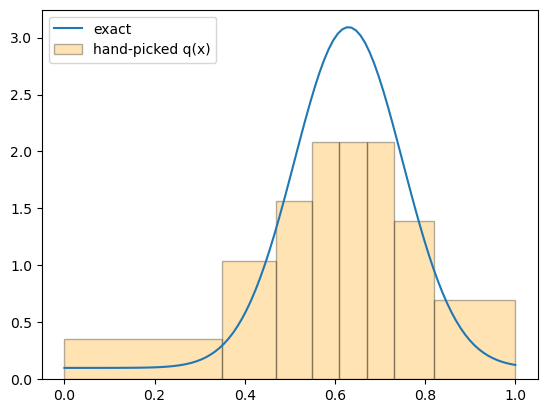

In [31]:
# copying the code again as reference
@njit
def toy(x, b, A, mu, sigma):
    return b + A*np.exp(-0.5*((x-mu)/sigma)**2)/(sigma*np.sqrt(2*np.pi))

xmin = 0
xmax = 1
x = np.linspace(xmin, xmax, 100)

b = 0.1
A = 0.9
mu = 0.63
sigma = 0.12

y = toy(x, b, A, mu, sigma)

# But then we now eyeball a q function, 
# just something biased towards the peak, 
# but compensates for that bias by making dx near that peak smaller
q_edges = np.array([xmin, .35, .47, .55, .61, .67, .73, .82, xmax])
q_bin_widths = np.diff(q_edges)
num_bins = len(q_bin_widths)
q_bin_heights = 1 / (num_bins * q_bin_widths)

plt.plot(x, y, label="exact")

plt.bar(
    q_edges[:-1], q_bin_heights,
    width=q_bin_widths,
    align="edge",
    color="orange",
    edgecolor="black",
    alpha=0.3,
    label="hand-picked q(x)",
)

plt.legend()
plt.show()

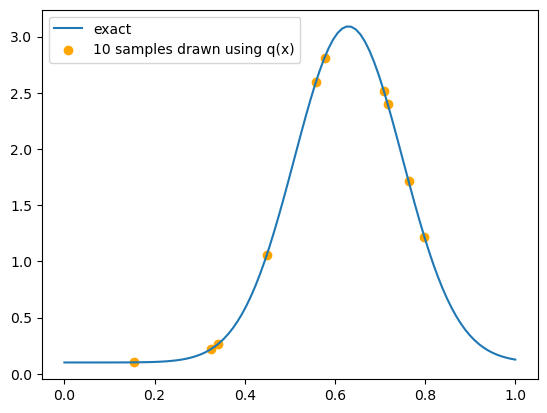

In [33]:
num_samples = 10
rng = np.random.default_rng(42)

# Choose a bin uniformly, then choose a position within it.
bin_index = rng.integers(num_bins, size=num_samples)
x_distribution = (
    q_edges[bin_index]
    + q_bin_widths[bin_index] * rng.random(num_samples)
)

q_distribution = q_bin_heights[bin_index]
y_distribution = toy(x_distribution, b, A, mu, sigma)

plt.plot(x, y, label='exact')
plt.scatter(
    x_distribution,
    y_distribution,
    color='orange',
    label=f'{num_samples} samples drawn using q(x)',
)
plt.legend()
plt.show()

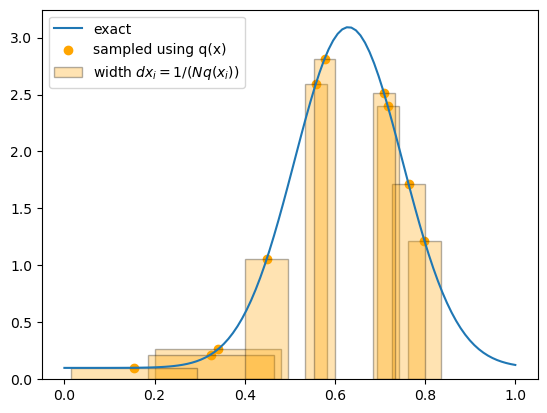

In [34]:
plt.plot(x, y, label='exact')
plt.scatter(
    x_distribution,
    y_distribution,
    color='orange',
    label='sampled using q(x)',
)

dx_distribution = 1 / (num_samples * q_distribution)

plt.bar(
    x_distribution,
    height=y_distribution,
    width=dx_distribution,
    align='center',
    color='orange',
    edgecolor='black',
    alpha=0.3,
    label=r'width $dx_i = 1/(Nq(x_i))$',
)

plt.legend()
plt.show()

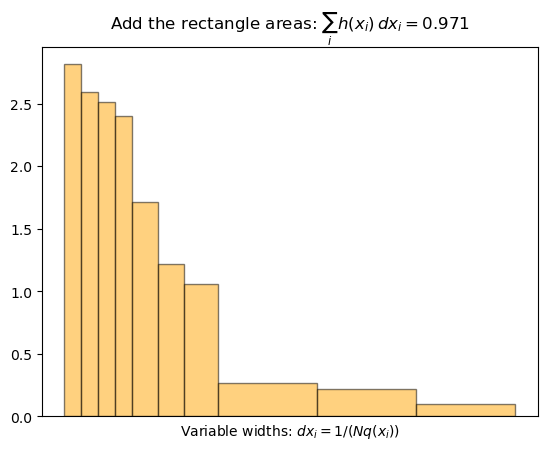

In [35]:
order = np.argsort(y_distribution)[::-1]
heights = y_distribution[order]
widths = dx_distribution[order]

positions = xmin + np.concatenate(([0.0], np.cumsum(widths[:-1])))
total_area = np.sum(heights * widths)

plt.bar(
    positions, heights,
    width=widths, align='edge',
    color='orange', edgecolor='black', alpha=0.5,
)

plt.xticks([])
plt.title(
    rf"Add the rectangle areas: $\sum_i h(x_i)\,dx_i = {total_area:.3f}$"
)
plt.xlabel(r"Variable widths: $dx_i = 1/(Nq(x_i))$")
plt.show()

but we don't want to rely on our eyes! these methods are particularly useful for high dimensional integrals where the eyes refuse to see.

# VEGAS

We picked the bin boundaries for $q(x)$ by eye. Now let's use an algorithm that relaxes or "learns" an initial guess into a better approximation of $q(x)$. This is the big idea of the VEGAS algorithm.

Remember our sum of rectangle areas:

$$
\sum_i h(x_i)\,dx_i
=
\frac{1}{N}\sum_i \frac{h(x_i)}{q(x_i)},
$$

where each rectangle has width

$$
dx_i = \frac{1}{Nq(x_i)}.
$$

We want the rectangle areas $$h(x_i)\,dx_i = h(x_i)/(Nq(x_i))$$ to be similar, so our answer depends less on which samples we draw. 
For our positive function, choosing $$q(x)=h(x)/\int_{x_{\min}}^{x_{\max}}h(t)\,dt$$ would make those areas identical, but the denominator is the integral we’re trying to find.

## Let the bins move

Start with $K$ equally wide bins. As before, choose a bin with probability $1/K$, then sample uniformly inside it.

If bin $j$ has width $dx_j$, the sampling density inside it is

$$
q(x) = \frac{1}{K\,dx_j}.
$$

Here, $dx_j$ is the width of a sampling bin; $dx_i$ above is the width assigned to an individual rectangle.

So we already have a way to change $q(x)$: move the bin boundaries. Narrower bins give a higher sampling density.

VEGAS repeats the following steps:

1. Draw samples using the current bins.
2. Calculate each sample's weighted contribution:
   $$
   w_i = \frac{h(x_i)}{q(x_i)}.
   $$
3. Score each bin using the average squared contribution of its samples:
   $$
   S_j = \frac{1}{n_j}\sum_{i:\,x_i\text{ in bin }j} w_i^2,
   $$
   where $n_j$ is the number of samples in that bin.
4. Smooth the scores and move the boundaries so that regions with larger scores receive more bins.

More bins in a region means narrower bins, which means more samples per unit $x$ there. Then we sample again and update the grid again.

## Why squared contributions?

The mean weight cannot measure improvement: its expectation is the integral, regardless of the sampling density. Consider these two sets of weights:

$$
(w_1,w_2)=(1,1)
\qquad\text{or}\qquad
(w_1,w_2)=(0,2).
$$

Both average to one, but their mean squares are one and two. With the mean fixed, minimizing the average squared weight minimizes variance, so it provides a useful loss. The bin scores show where that loss comes from.
## Back to the u-sub

Each bin represents an equal interval in $u$, but its width in $x$ can change. Moving the boundaries changes the slope of $x(u)$ inside each bin:

$$
\frac{dx}{du} = K\,dx_j = \frac{1}{q(x)}.
$$

VEGAS is learning a piecewise linear u-substitution from the function values.

For our implementation, we will train the grid first, then freeze it and draw fresh samples. We add the rectangle areas as before:

$$
\sum_i h(x_i)\,dx_i
=
\frac{1}{N}\sum_i w_i.
$$

The standard error of that sum is

$$
\mathrm{SE}\left(\sum_i h(x_i)\,dx_i\right)
=
\frac{s_w}{\sqrt{N}},
$$

where $s_w$ is the sample standard deviation of the weights.

## 1. Draw samples from the current grid

Start with equally wide bins. Choose a bin uniformly, then choose a position uniformly inside it.

Each green bar shows the sampling density inside one bin:

$$
q(x) = \frac{1}{K\,dx_j}.
$$

We'll follow the purple bin through the next few steps.

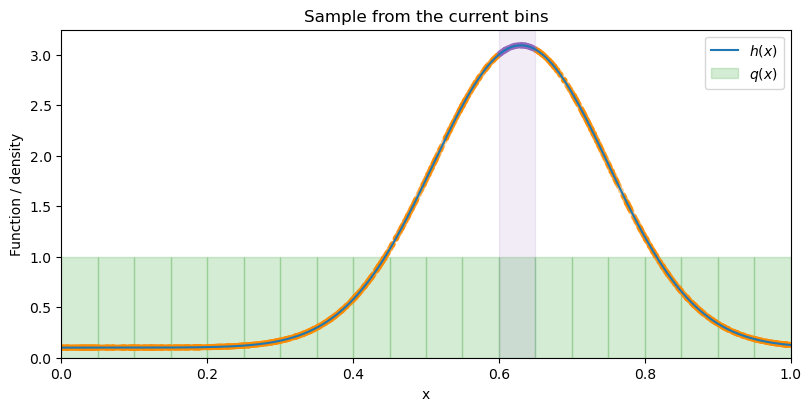

In [38]:
def sample_grid(edges, num_samples, rng):
    widths = np.diff(edges)
    num_bins = len(widths)

    if num_bins < 1 or np.any(widths <= 0):
        raise ValueError("Bin edges must increase strictly.")

    bin_index = rng.integers(num_bins, size=num_samples)
    xs = edges[bin_index] + widths[bin_index] * rng.random(num_samples)
    qs = 1 / (num_bins * widths[bin_index])

    return xs, qs, bin_index


num_bins = 20
training_samples = 2000
num_iterations = 6
alpha = 1.5
training_seed = 143

initial_edges = np.linspace(xmin, xmax, num_bins + 1)
bin_widths = np.diff(initial_edges)
bin_centers = (initial_edges[:-1] + initial_edges[1:]) / 2
initial_density = 1 / (num_bins * bin_widths)

rng = np.random.default_rng(training_seed)
train_x, train_q, train_bin = sample_grid(
    initial_edges, training_samples, rng,
)
train_y = toy(train_x, b, A, mu, sigma)

grid = np.linspace(xmin, xmax, 2000)
h_grid = toy(grid, b, A, mu, sigma)

focus_bin = np.argmin(np.abs(bin_centers - mu))
sample_colors = np.where(
    train_bin == focus_bin, "tab:purple", "darkorange",
)

plt.figure("vegas_samples", figsize=(8, 4), layout="constrained")

plt.bar(
    initial_edges[:-1], initial_density,
    width=bin_widths, align="edge",
    color="tab:green", edgecolor="tab:green", alpha=0.20,
    label=r"$q(x)$",
)
plt.plot(grid, h_grid, color="tab:blue", label=r"$h(x)$")
plt.scatter(train_x, train_y, c=sample_colors, s=12, alpha=0.35)
plt.axvspan(
    initial_edges[focus_bin], initial_edges[focus_bin + 1],
    color="tab:purple", alpha=0.12,
)
plt.xlim(xmin, xmax)
plt.xlabel("x")
plt.ylabel("Function / density")
plt.title("Sample from the current bins")
plt.legend()
plt.show()

## 2. Calculate the rectangle areas

Each rectangle has width

$$
dx_i = \frac{1}{Nq(x_i)}.
$$

Its area is therefore

$$
h(x_i)\,dx_i
=
\frac{1}{N}\frac{h(x_i)}{q(x_i)}
=
\frac{w_i}{N}.
$$

Keep the original samples on the left. On the right, divide their heights by the sampling density.

For our initial uniform density on $[0,1]$, $q(x)=1$, so these heights initially stay the same.

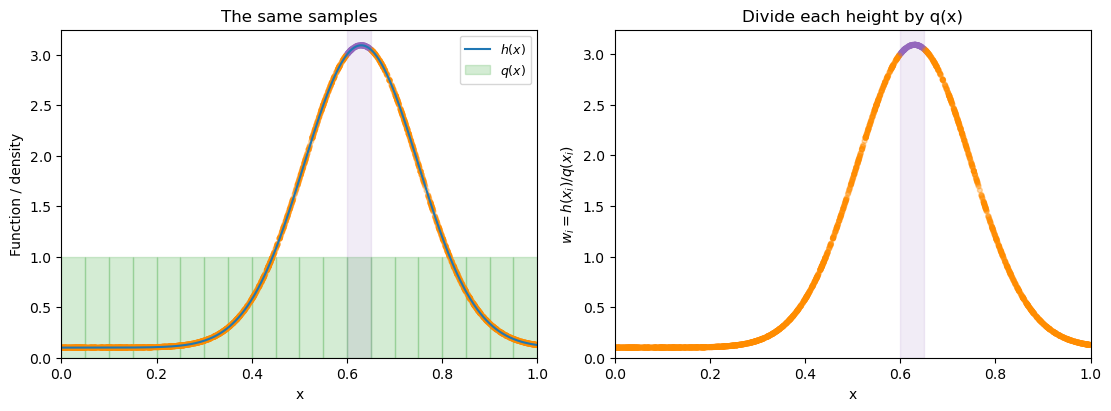

In [39]:
weights = train_y / train_q
rectangle_widths = 1 / (training_samples * train_q)
rectangle_areas = train_y * rectangle_widths

fig, axes = plt.subplots(
    1, 2, num="vegas_weights",
    figsize=(11, 4), layout="constrained",
)

axes[0].bar(
    initial_edges[:-1], initial_density,
    width=bin_widths, align="edge",
    color="tab:green", edgecolor="tab:green", alpha=0.20,
    label=r"$q(x)$",
)
axes[0].plot(grid, h_grid, color="tab:blue", label=r"$h(x)$")
axes[0].scatter(
    train_x, train_y, c=sample_colors, s=12, alpha=0.35,
)
axes[0].set_title("The same samples")
axes[0].set_ylabel("Function / density")
axes[0].legend(fontsize=9)

axes[1].scatter(
    train_x, weights, c=sample_colors, s=12, alpha=0.35,
)
axes[1].set_title("Divide each height by q(x)")
axes[1].set_ylabel(r"$w_i = h(x_i)/q(x_i)$")

for ax in axes:
    ax.axvspan(
        initial_edges[focus_bin], initial_edges[focus_bin + 1],
        color="tab:purple", alpha=0.12,
    )
    ax.set_xlim(xmin, xmax)
    ax.set_xlabel("x")
    ax.set_ylim(bottom=0)

plt.show()

## 3. Score the bins

Keep those weights on the left.

On the right, square each weight and average the squared values inside each bin:

$$
S_j = \frac{1}{n_j}\sum_{i:\,x_i\text{ in bin }j} w_i^2.
$$

The dots show the squared weights. Each orange bar shows their average within one bin. The purple line marks the average in our highlighted bin.

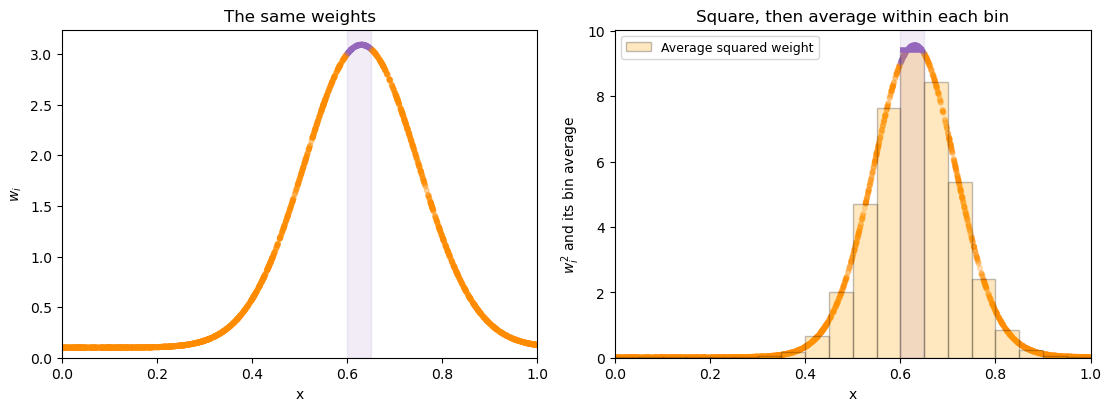

In [40]:
def score_bins(bin_index, weights, num_bins):
    counts = np.bincount(bin_index, minlength=num_bins)

    if np.any(counts == 0):
        raise ValueError("A bin has no samples. Increase the training batch.")

    squared_totals = np.bincount(
        bin_index, weights=weights**2, minlength=num_bins,
    )

    return squared_totals / counts


scores = score_bins(train_bin, weights, num_bins)

fig, axes = plt.subplots(
    1, 2, num="vegas_scores",
    figsize=(11, 4), layout="constrained",
)

axes[0].scatter(
    train_x, weights, c=sample_colors, s=12, alpha=0.35,
)
axes[0].set_title("The same weights")
axes[0].set_ylabel(r"$w_i$")

axes[1].scatter(
    train_x, weights**2, c=sample_colors, s=12, alpha=0.25,
)
axes[1].bar(
    initial_edges[:-1], scores,
    width=bin_widths, align="edge",
    color="orange", edgecolor="black", alpha=0.25,
    label="Average squared weight",
)
axes[1].hlines(
    scores[focus_bin],
    initial_edges[focus_bin], initial_edges[focus_bin + 1],
    color="tab:purple", linewidth=4,
)
axes[1].set_title("Square, then average within each bin")
axes[1].set_ylabel(r"$w_i^2$ and its bin average")
axes[1].legend(fontsize=9)

for ax in axes:
    ax.axvspan(
        initial_edges[focus_bin], initial_edges[focus_bin + 1],
        color="tab:purple", alpha=0.12,
    )
    ax.set_xlim(xmin, xmax)
    ax.set_xlabel("x")
    ax.set_ylim(bottom=0)

plt.show()

## 4. Smooth the scores and soften the update

Keep the squared samples and their bin averages on the left.

First, mix each score with its neighbors. Then compress the differences between large and small scores.

The parameter $\alpha$ controls how strongly those differences affect the update. Smaller values give gentler updates; $\alpha=0$ leaves the grid unchanged.

On the right, divide each set of scores by its own sum so we can compare their shapes.

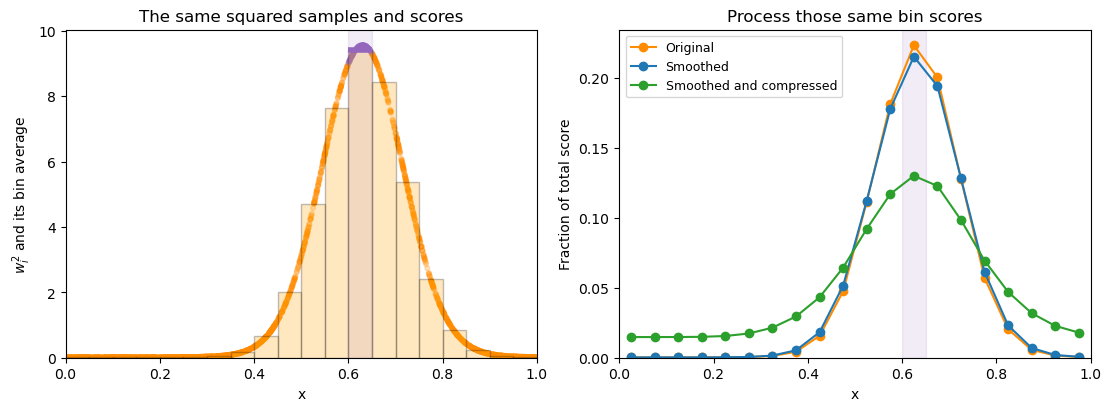

In [41]:
def smooth_and_compress(scores, alpha):
    if len(scores) < 2:
        raise ValueError("Adaptation requires at least two bins.")
    if np.any(scores <= 0) or not np.all(np.isfinite(scores)):
        raise ValueError("Scores must be finite and positive.")
    if alpha < 0:
        raise ValueError("alpha must be nonnegative.")

    smoothed = np.convolve(
        np.pad(scores, (1, 1), mode="edge"),
        np.array([1, 6, 1]) / 8,
        mode="valid",
    )

    normalized = smoothed / smoothed.sum()
    importance = ((normalized - 1) / np.log(normalized))**alpha

    return smoothed, importance


smoothed, importance = smooth_and_compress(scores, alpha)

fig, axes = plt.subplots(
    1, 2, num="vegas_smoothing",
    figsize=(11, 4), layout="constrained",
)

axes[0].scatter(
    train_x, weights**2, c=sample_colors, s=12, alpha=0.25,
)
axes[0].bar(
    initial_edges[:-1], scores,
    width=bin_widths, align="edge",
    color="orange", edgecolor="black", alpha=0.25,
)
axes[0].hlines(
    scores[focus_bin],
    initial_edges[focus_bin], initial_edges[focus_bin + 1],
    color="tab:purple", linewidth=4,
)
axes[0].set_title("The same squared samples and scores")
axes[0].set_ylabel(r"$w_i^2$ and its bin average")

axes[1].plot(
    bin_centers, scores / scores.sum(),
    "o-", color="darkorange", label="Original",
)
axes[1].plot(
    bin_centers, smoothed / smoothed.sum(),
    "o-", color="tab:blue", label="Smoothed",
)
axes[1].plot(
    bin_centers, importance / importance.sum(),
    "o-", color="tab:green", label="Smoothed and compressed",
)
axes[1].set_title("Process those same bin scores")
axes[1].set_ylabel("Fraction of total score")
axes[1].legend(fontsize=9)

for ax in axes:
    ax.axvspan(
        initial_edges[focus_bin], initial_edges[focus_bin + 1],
        color="tab:purple", alpha=0.12,
    )
    ax.set_xlim(xmin, xmax)
    ax.set_xlabel("x")
    ax.set_ylim(bottom=0)

plt.show()

## 5. Move the boundaries

Keep the processed scores on the left.

Treat each processed score as an amount distributed uniformly across its old bin. Add those amounts from left to right.

Place the new boundaries at equal steps through that cumulative total. Where the total rises quickly, the new boundaries end up closer together.

The right panel shows the resulting bins and their new sampling density.

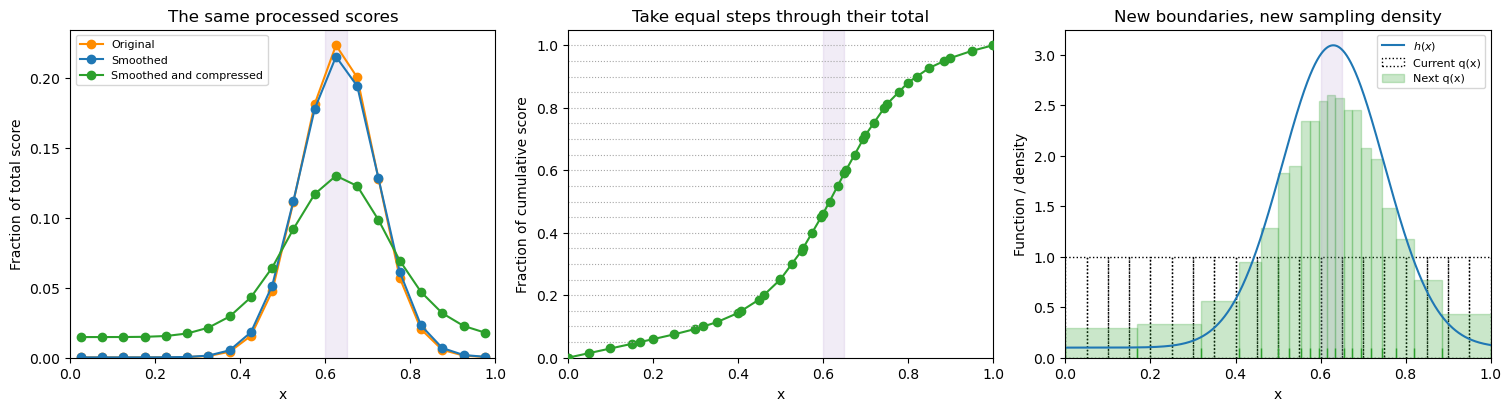

In [42]:
def move_boundaries(edges, importance):
    cumulative = np.concatenate(([0.0], np.cumsum(importance)))
    targets = np.linspace(0, cumulative[-1], len(edges))
    updated_edges = np.interp(targets, cumulative, edges)

    if np.any(np.diff(updated_edges) <= 0):
        raise ValueError("The update produced a collapsed bin.")

    return updated_edges


updated_edges = move_boundaries(initial_edges, importance)
updated_widths = np.diff(updated_edges)
updated_density = 1 / (num_bins * updated_widths)

cumulative = np.concatenate(([0.0], np.cumsum(importance)))
cumulative_fraction = cumulative / cumulative[-1]
levels = np.linspace(0, 1, num_bins + 1)

fig, axes = plt.subplots(
    1, 3, num="vegas_boundary_update",
    figsize=(15, 4), layout="constrained",
)

axes[0].plot(
    bin_centers, scores / scores.sum(),
    "o-", color="darkorange", label="Original",
)
axes[0].plot(
    bin_centers, smoothed / smoothed.sum(),
    "o-", color="tab:blue", label="Smoothed",
)
axes[0].plot(
    bin_centers, importance / importance.sum(),
    "o-", color="tab:green", label="Smoothed and compressed",
)
axes[0].set_title("The same processed scores")
axes[0].set_ylabel("Fraction of total score")
axes[0].legend(fontsize=8)

axes[1].plot(
    initial_edges, cumulative_fraction,
    "o-", color="tab:green",
)
axes[1].hlines(
    levels, xmin, updated_edges,
    colors="0.65", linestyles=":", linewidth=0.8,
)
axes[1].scatter(updated_edges, levels, color="tab:green", zorder=3)
axes[1].set_title("Take equal steps through their total")
axes[1].set_ylabel("Fraction of cumulative score")

axes[2].bar(
    initial_edges[:-1], initial_density,
    width=bin_widths, align="edge",
    facecolor="none", edgecolor="black", linestyle=":",
    label="Current q(x)",
)
axes[2].bar(
    updated_edges[:-1], updated_density,
    width=updated_widths, align="edge",
    color="tab:green", edgecolor="tab:green", alpha=0.25,
    label="Next q(x)",
)
axes[2].plot(grid, h_grid, color="tab:blue", label=r"$h(x)$")
axes[2].plot(
    updated_edges, np.zeros_like(updated_edges),
    "|", color="tab:green", markersize=14,
)
axes[2].set_title("New boundaries, new sampling density")
axes[2].set_ylabel("Function / density")
axes[2].legend(fontsize=8)

for ax in axes:
    ax.axvspan(
        initial_edges[focus_bin], initial_edges[focus_bin + 1],
        color="tab:purple", alpha=0.12,
    )
    ax.set_xlim(xmin, xmax)
    ax.set_xlabel("x")
    ax.set_ylim(bottom=0)

plt.show()

## 6. Do it again

Now sample from the updated grid, calculate new weights, score the bins, and move the boundaries again.

The function below puts those same steps into a loop. We save each grid so we can watch it change.

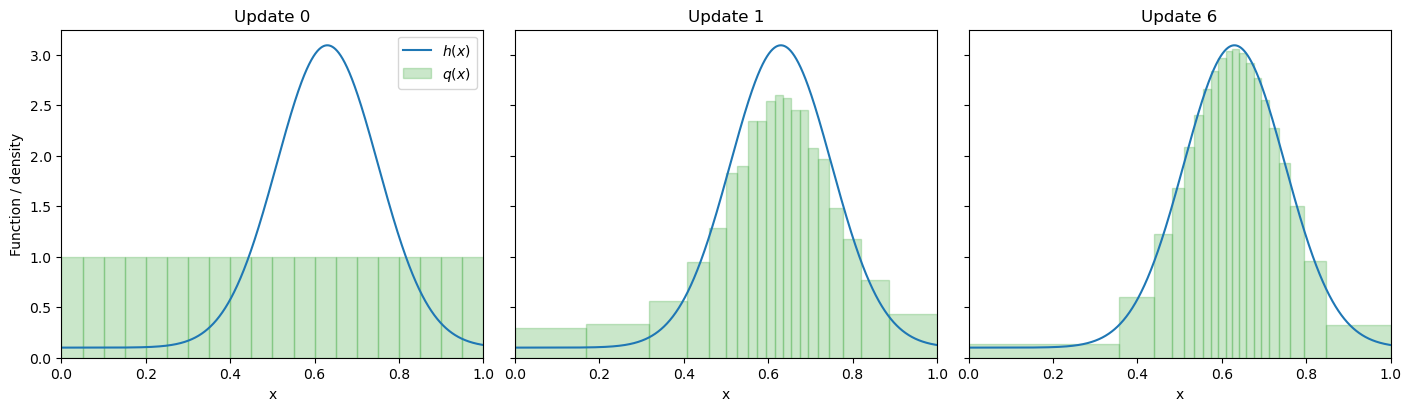

In [43]:
def train_grid(
    num_bins, num_samples, iterations, alpha, seed,
    xmin, xmax, b, A, mu, sigma,
):
    if num_bins < 2 or iterations < 1:
        raise ValueError("Require at least two bins and one iteration.")

    edges = np.linspace(xmin, xmax, num_bins + 1)
    history = [edges.copy()]
    rng = np.random.default_rng(seed)

    for iteration in range(iterations):
        xs, qs, bin_index = sample_grid(edges, num_samples, rng)
        weights = toy(xs, b, A, mu, sigma) / qs

        scores = score_bins(bin_index, weights, num_bins)
        smoothed, importance = smooth_and_compress(scores, alpha)
        edges = move_boundaries(edges, importance)

        history.append(edges.copy())

    return edges, history


final_edges, history = train_grid(
    num_bins, training_samples, num_iterations, alpha, training_seed,
    xmin, xmax, b, A, mu, sigma,
)

fig, axes = plt.subplots(
    1, 3, num="vegas_grid_history",
    figsize=(14, 4), sharey=True, layout="constrained",
)

for ax, step in zip(axes, (0, 1, num_iterations)):
    edges = history[step]
    widths = np.diff(edges)
    density = 1 / (num_bins * widths)

    ax.bar(
        edges[:-1], density,
        width=widths, align="edge",
        color="tab:green", edgecolor="tab:green", alpha=0.25,
        label=r"$q(x)$",
    )
    ax.plot(grid, h_grid, color="tab:blue", label=r"$h(x)$")
    ax.set_xlim(xmin, xmax)
    ax.set_xlabel("x")
    ax.set_title("Update {}".format(step))

axes[0].set_ylabel("Function / density")
axes[0].legend()
plt.show()

## 7. Look at the u-sub we learned

Follow the purple bin and the purple diamond through all three panels.

First, we have points on $h(x)$.

Next, move those same points from $x$ to $u$, keeping their heights unchanged. The unequal bins in $x$ become equal bins in $u$.

Finally, multiply their heights by

$$
\frac{dx}{du} = \frac{1}{q(x)}.
$$

The last panel shows the values we now average. Both the horizontal stretching and the height correction come from the learned grid.

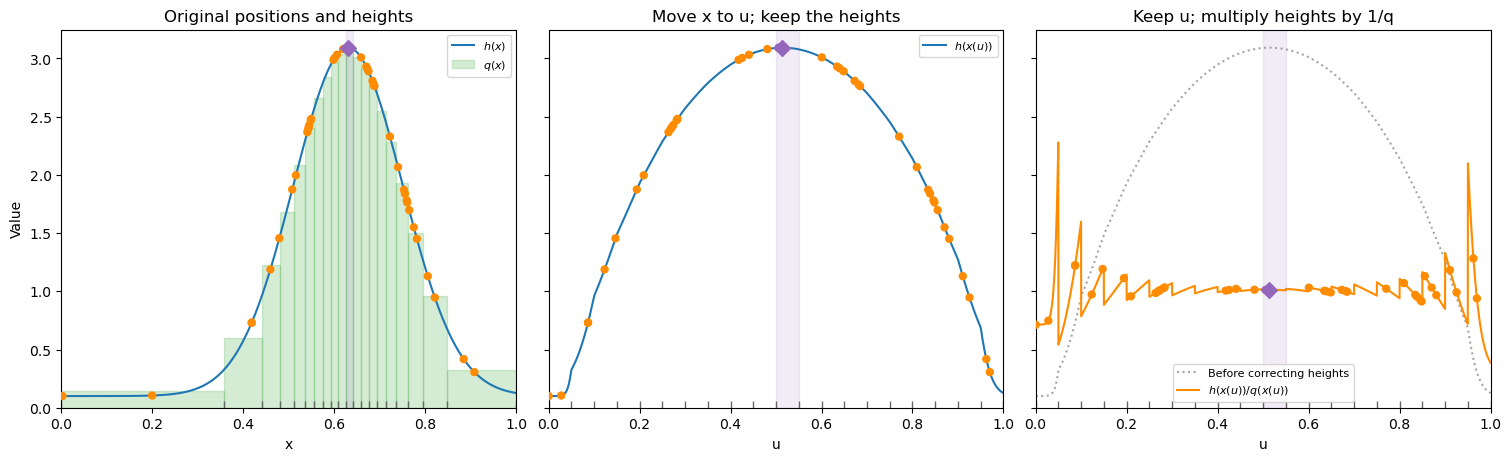

In [44]:
map_bins = len(final_edges) - 1
final_widths = np.diff(final_edges)
final_density = 1 / (map_bins * final_widths)
u_edges = np.linspace(0, 1, map_bins + 1)

visual_rng = np.random.default_rng(145)
u_samples = visual_rng.random(40)
sample_bins = np.floor(map_bins * u_samples).astype(int)

mapped_x = np.interp(u_samples, u_edges, final_edges)
sample_heights = toy(mapped_x, b, A, mu, sigma)
sample_q = final_density[sample_bins]
corrected_heights = sample_heights / sample_q

u_grid = (np.arange(4000) + 0.5) / 4000
grid_bins = np.floor(map_bins * u_grid).astype(int)
mapped_grid = np.interp(u_grid, u_edges, final_edges)
mapped_heights = toy(mapped_grid, b, A, mu, sigma)
corrected_curve = mapped_heights / final_density[grid_bins]

trace = np.argmax(sample_heights)
trace_bin = sample_bins[trace]
colors = np.where(
    sample_bins == trace_bin, "tab:purple", "darkorange",
)

fig, axes = plt.subplots(
    1, 3, num="vegas_usub",
    figsize=(15, 4.5), sharey=True, layout="constrained",
)

axes[0].bar(
    final_edges[:-1], final_density,
    width=final_widths, align="edge",
    color="tab:green", edgecolor="tab:green", alpha=0.20,
    label=r"$q(x)$",
)
axes[0].plot(grid, h_grid, color="tab:blue", label=r"$h(x)$")
axes[0].set_title("Original positions and heights")
axes[0].set_xlabel("x")
axes[0].set_xlim(xmin, xmax)
axes[0].set_ylabel("Value")
axes[0].legend(fontsize=8)

axes[1].plot(
    u_grid, mapped_heights,
    color="tab:blue", label=r"$h(x(u))$",
)
axes[1].set_title("Move x to u; keep the heights")
axes[1].set_xlabel("u")
axes[1].set_xlim(0, 1)
axes[1].legend(fontsize=8)

axes[2].plot(
    u_grid, mapped_heights,
    color="0.65", linestyle=":", label="Before correcting heights",
)
axes[2].plot(
    u_grid, corrected_curve,
    color="darkorange", label=r"$h(x(u))/q(x(u))$",
)
axes[2].set_title("Keep u; multiply heights by 1/q")
axes[2].set_xlabel("u")
axes[2].set_xlim(0, 1)
axes[2].legend(fontsize=8)

positions = (mapped_x, u_samples, u_samples)
heights = (sample_heights, sample_heights, corrected_heights)
boundaries = (final_edges, u_edges, u_edges)

for ax, horizontal, vertical, edges in zip(
    axes, positions, heights, boundaries,
):
    ax.axvspan(
        edges[trace_bin], edges[trace_bin + 1],
        color="tab:purple", alpha=0.12,
    )
    ax.plot(
        edges, np.zeros_like(edges),
        "|", color="0.4", markersize=10,
    )
    ax.scatter(horizontal, vertical, c=colors, s=25, zorder=3)
    ax.scatter(
        horizontal[trace], vertical[trace],
        marker="D", color="tab:purple", s=65, zorder=4,
    )
    ax.set_ylim(bottom=0)

plt.show()

## 8. Freeze the grid and add the rectangle areas

Keep the final grid fixed and draw fresh samples.

Our answer is still

$$
\sum_i h(x_i)\,dx_i
=
\frac{1}{N}\sum_i w_i,
$$

with standard error

$$
\frac{s_{w}}{\sqrt{N}}.
$$

Use 20 samples here so we can label each rectangle's area. Increase that number when you want a more precise estimate.

The packed rectangles keep their individual widths. Their combined width fluctuates; we don't rescale them to fit the original range.

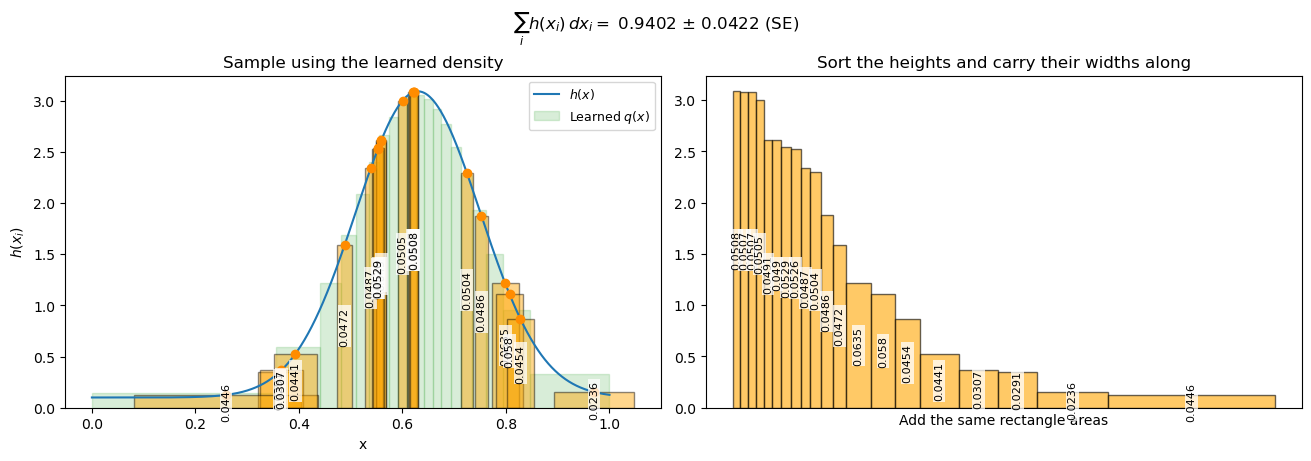

In [45]:
def integrate_grid(edges, num_samples, seed, b, A, mu, sigma):
    if num_samples < 2:
        raise ValueError("At least two samples are needed for a standard error.")

    rng = np.random.default_rng(seed)
    xs, qs, bin_index = sample_grid(edges, num_samples, rng)
    ys = toy(xs, b, A, mu, sigma)

    widths = 1 / (num_samples * qs)
    weights = ys / qs

    area = np.sum(ys * widths)
    standard_error = np.std(weights, ddof=1) / np.sqrt(num_samples)

    return area, standard_error, xs, ys, widths


production_samples = 20
production_seed = 144

area, standard_error, xs, ys, widths = integrate_grid(
    final_edges, production_samples, production_seed, b, A, mu, sigma,
)

order = np.argsort(ys)[::-1]
sorted_heights = ys[order]
sorted_widths = widths[order]
positions = xmin + np.concatenate(([0.0], np.cumsum(sorted_widths[:-1])))

fig, axes = plt.subplots(
    1, 2, num="vegas_rectangle_sum",
    figsize=(13, 4.5), layout="constrained",
)
fig.suptitle(
    r"$\sum_i h(x_i)\,dx_i =$ "
    + "{:.4f} ± {:.4f} (SE)".format(area, standard_error)
)

axes[0].bar(
    final_edges[:-1],
    1 / ((len(final_edges) - 1) * np.diff(final_edges)),
    width=np.diff(final_edges), align="edge",
    color="tab:green", edgecolor="tab:green", alpha=0.18,
    label=r"Learned $q(x)$", zorder=0,
)
axes[0].plot(
    grid, h_grid, color="tab:blue", label=r"$h(x)$", zorder=3,
)
axes[0].bar(
    xs, ys, width=widths, align="center",
    color="orange", edgecolor="black", alpha=0.45, zorder=2,
)
axes[0].scatter(xs, ys, color="darkorange", zorder=4)

for xi, height, width in zip(xs, ys, widths):
    axes[0].text(
        xi, height / 2, "{:.3g}".format(height * width),
        ha="center", va="center", rotation=90, fontsize=8, zorder=5,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=1),
    )

axes[0].set_xlabel("x")
axes[0].set_ylabel(r"$h(x_i)$")
axes[0].set_title("Sample using the learned density")
axes[0].legend(fontsize=9)

axes[1].bar(
    positions, sorted_heights,
    width=sorted_widths, align="edge",
    color="orange", edgecolor="black", alpha=0.60,
)

for position, height, width in zip(
    positions, sorted_heights, sorted_widths,
):
    axes[1].text(
        position + width / 2, height / 2,
        "{:.3g}".format(height * width),
        ha="center", va="center", rotation=90, fontsize=8,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=1),
    )

axes[1].set_xticks([])
axes[1].set_xlabel("Add the same rectangle areas")
axes[1].set_title("Sort the heights and carry their widths along")

plt.show()

## Why smooth and compress?

Use our original function, with only four samples per bin so each score is based on little information.

The blue curve and sampled points stay the same in every column.

- **Top:** process the scores from those samples.
- **Bottom:** compare the resulting sampling density to the original function.

Smoothing gives neighboring bins some attention. Compression makes the update less aggressive while we are still learning where to put the bins.

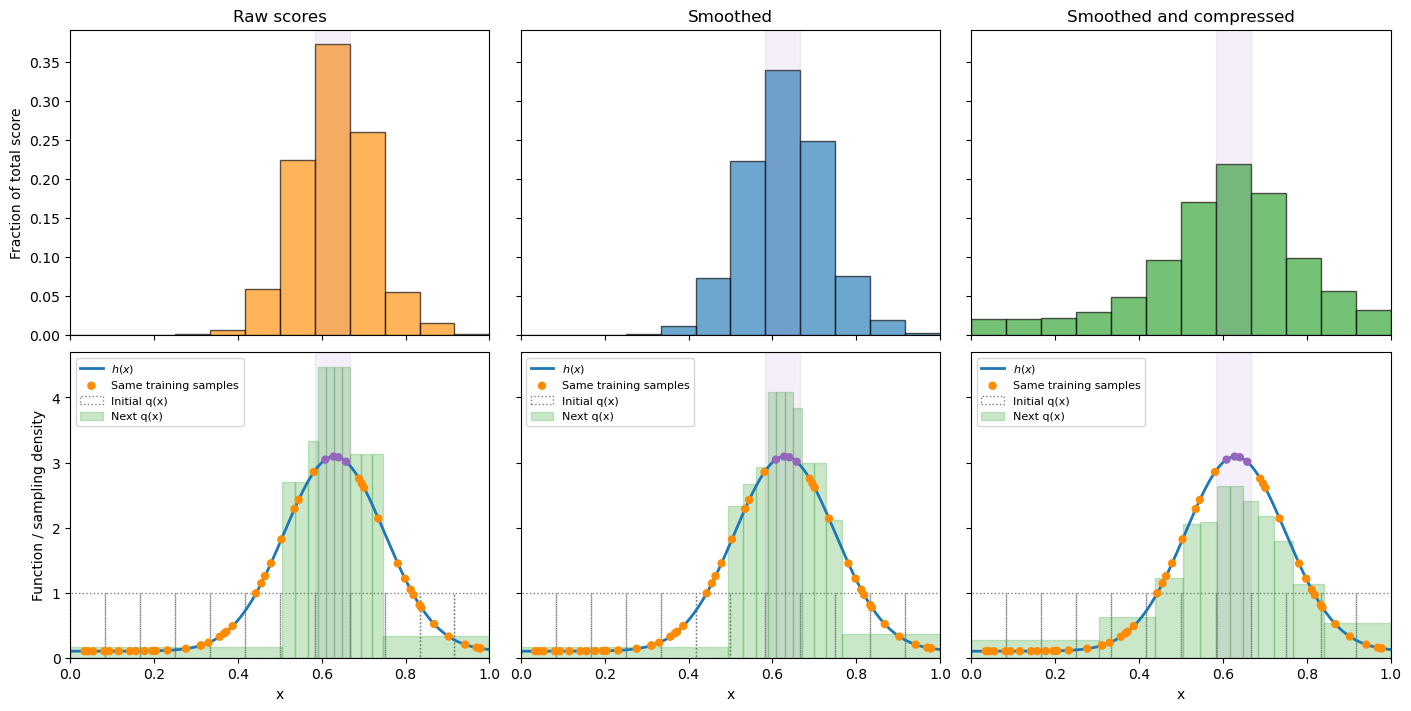

In [47]:
demo_num_bins = 12
demo_samples_per_bin = 4
demo_alpha = 1.5

demo_edges = np.linspace(xmin, xmax, demo_num_bins + 1)
demo_widths = np.diff(demo_edges)
demo_rng = np.random.default_rng(143)

# Give each bin four uniformly placed samples.
demo_index = np.repeat(
    np.arange(demo_num_bins), demo_samples_per_bin,
)
demo_x = (
    demo_edges[demo_index]
    + demo_widths[demo_index] * demo_rng.random(len(demo_index))
)
demo_q = 1 / (demo_num_bins * demo_widths[demo_index])
demo_y = toy(demo_x, b, A, mu, sigma)
demo_weights = demo_y / demo_q

# Calculate the actual scores from those samples.
demo_counts = np.bincount(demo_index, minlength=demo_num_bins)
demo_raw = np.bincount(
    demo_index,
    weights=demo_weights**2,
    minlength=demo_num_bins,
) / demo_counts

# Smooth, then compress.
demo_smoothed = np.convolve(
    np.pad(demo_raw, (1, 1), mode="edge"),
    np.array([1, 6, 1]) / 8,
    mode="valid",
)
demo_normalized = demo_smoothed / demo_smoothed.sum()
demo_compressed = (
    (demo_normalized - 1) / np.log(demo_normalized)
)**demo_alpha

demo_grid = np.linspace(xmin, xmax, 2000)
demo_h = toy(demo_grid, b, A, mu, sigma)

demo_focus = np.argmax(demo_raw)
demo_sample_colors = np.where(
    demo_index == demo_focus, "tab:purple", "darkorange",
)

demo_stages = (demo_raw, demo_smoothed, demo_compressed)
demo_titles = ("Raw scores", "Smoothed", "Smoothed and compressed")
demo_colors = ("darkorange", "tab:blue", "tab:green")

demo_fig, demo_axes = plt.subplots(
    2, 3, num="vegas_smoothing_original_function",
    figsize=(14, 7), sharex=True, sharey="row",
    layout="constrained",
)

for demo_column, demo_scores in enumerate(demo_stages):
    demo_axes[0, demo_column].bar(
        demo_edges[:-1], demo_scores / demo_scores.sum(),
        width=demo_widths, align="edge",
        color=demo_colors[demo_column],
        edgecolor="black", alpha=0.65,
    )
    demo_axes[0, demo_column].set_title(demo_titles[demo_column])

    # Move the boundaries using this column's scores.
    demo_cumulative = np.concatenate(([0.0], np.cumsum(demo_scores)))
    demo_targets = np.linspace(
        0, demo_cumulative[-1], demo_num_bins + 1,
    )
    demo_new_edges = np.interp(
        demo_targets, demo_cumulative, demo_edges,
    )
    demo_new_widths = np.diff(demo_new_edges)
    demo_new_q = 1 / (demo_num_bins * demo_new_widths)

    # Keep the original function and samples visible.
    demo_axes[1, demo_column].bar(
        demo_edges[:-1], 1 / (demo_num_bins * demo_widths),
        width=demo_widths, align="edge",
        facecolor="none", edgecolor="0.5", linestyle=":",
        label="Initial q(x)",
    )
    demo_axes[1, demo_column].bar(
        demo_new_edges[:-1], demo_new_q,
        width=demo_new_widths, align="edge",
        color="tab:green", edgecolor="tab:green", alpha=0.25,
        label="Next q(x)",
    )
    demo_axes[1, demo_column].plot(
        demo_grid, demo_h,
        color="tab:blue", linewidth=2, label=r"$h(x)$",
    )
    demo_axes[1, demo_column].scatter(
        demo_x, demo_y,
        c=demo_sample_colors, s=25, zorder=3,
        label="Same training samples",
    )
    demo_axes[1, demo_column].set_xlabel("x")
    demo_axes[1, demo_column].legend(fontsize=8)

    for demo_row in range(2):
        demo_axes[demo_row, demo_column].axvspan(
            demo_edges[demo_focus], demo_edges[demo_focus + 1],
            color="tab:purple", alpha=0.10,
        )
        demo_axes[demo_row, demo_column].set_xlim(xmin, xmax)
        demo_axes[demo_row, demo_column].set_ylim(bottom=0)

demo_axes[0, 0].set_ylabel("Fraction of total score")
demo_axes[1, 0].set_ylabel("Function / sampling density")

plt.show()